# Building a Minimal Vision-Language Model from Scratch

**Week 2 deliverable** — a small VLM implemented entirely from first principles: a Vision Transformer encoder, a projection layer, and a causal text decoder, trained on an image-captioning dataset.

This follows the pattern from Uygar Kurt's *"Implement and Train VLMs From Scratch – PyTorch"* video and the `seemore` reference implementation (see Section 4.3 of the reading plan), and deliberately mirrors the architectural lineage covered in Week 1's literature review:

| Component | This notebook | What it echoes from the papers |
|---|---|---|
| Vision encoder | `ViTEncoder` (trained from scratch) | CLIP's ViT, but untrained/uninitialized here |
| Connector | `Projector` (single linear layer) | LLaVA's linear projector (the simplest connector on our reading list) |
| Text decoder | `TextDecoder` (mini causal Transformer) | Stands in for the frozen/pretrained LLM that Flamingo, BLIP-2, and LLaVA all bolt onto |

**Goal:** understand the *mechanics* of how vision and language get fused — not to match production VLM performance. Everything here is small enough to train in minutes on a laptop CPU/GPU, by design.

**Dataset assumption (adjust as needed):** this notebook expects a Flickr8k-style layout — a folder of images plus a `captions.txt` file with `image_name,caption` rows (multiple caption rows per image is fine). Flickr8k is easy to obtain (e.g. via Kaggle: `adityajn105/flickr8k`) and is roughly the right size (~8K images) for a quick from-scratch run. If you're instead using the exact dataset from the reference repo/video, just point `IMAGE_DIR` and `CAPTIONS_FILE` below at that data — the rest of the pipeline doesn't care where the data came from as long as it's in `(image_path, caption)` pairs.


## 1. Setup

In [1]:
import os
import math
import random
import json
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T

torch.manual_seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)


Using device: mps


## 2. Configuration

Kept intentionally small so this runs fast on modest hardware. Bump these up once the pipeline is verified to work end-to-end on your machine.

In [ ]:
# --- Data paths: point these at your local dataset ---
IMAGE_DIR = "../data/flickr8k/Images"          # folder of .jpg images
CAPTIONS_FILE = "../data/flickr8k/captions.txt"  # image_name,caption per line (with header)

# --- Model / training config ---
IMG_SIZE = 96          # small on purpose -- bump to 224 for a more realistic run
PATCH_SIZE = 16
EMBED_DIM = 192
VIT_DEPTH = 4
DECODER_DEPTH = 4
NUM_HEADS = 4
DROPOUT = 0.1
MAX_TEXT_LEN = 32       # max caption length (in tokens), including BOS/EOS
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
NUM_EPOCHS = 5          # small dataset + small model -> a handful of epochs already shows learning


## 3. Tokenizer

For a model this small, a full BPE tokenizer (like a production LLM would use) is overkill. We build a simple **word-level tokenizer** from the captions themselves -- this keeps the vocabulary small and the whole pipeline transparent, which is the point of a from-scratch exercise.

In [3]:
class SimpleTokenizer:
    """A minimal word-level tokenizer built from the training captions.

    Real VLMs use a subword tokenizer shared with a pretrained LLM. We build
    our own tiny vocabulary here since we're also building the "LLM" (the
    TextDecoder) from scratch -- there's no pretrained tokenizer to reuse.
    """

    PAD, BOS, EOS, UNK = "<pad>", "<bos>", "<eos>", "<unk>"

    def __init__(self):
        self.word2id = {}
        self.id2word = {}

    def build_vocab(self, captions, min_freq=2):
        freq = {}
        for cap in captions:
            for word in cap.lower().strip().split():
                freq[word] = freq.get(word, 0) + 1
        vocab = [self.PAD, self.BOS, self.EOS, self.UNK] + sorted(
            [w for w, c in freq.items() if c >= min_freq]
        )
        self.word2id = {w: i for i, w in enumerate(vocab)}
        self.id2word = {i: w for w, i in self.word2id.items()}
        return len(vocab)

    @property
    def vocab_size(self):
        return len(self.word2id)

    @property
    def pad_id(self):
        return self.word2id[self.PAD]

    @property
    def bos_id(self):
        return self.word2id[self.BOS]

    @property
    def eos_id(self):
        return self.word2id[self.EOS]

    def encode(self, caption, max_len):
        words = caption.lower().strip().split()
        ids = [self.bos_id] + [
            self.word2id.get(w, self.word2id[self.UNK]) for w in words
        ] + [self.eos_id]
        ids = ids[:max_len]
        ids += [self.pad_id] * (max_len - len(ids))
        return ids

    def decode(self, ids):
        words = []
        for i in ids:
            w = self.id2word.get(int(i), self.UNK)
            if w == self.EOS:
                break
            if w not in (self.PAD, self.BOS):
                words.append(w)
        return " ".join(words)


## 4. Dataset

Reads `(image_path, caption)` pairs from the captions file. Each `__getitem__` call returns one image + one of its captions (a single image with 5 captions in the file becomes 5 training examples, which is standard practice for caption datasets).

In [4]:
class CaptionDataset(Dataset):
    def __init__(self, image_dir, captions_file, tokenizer, transform, max_len):
        self.image_dir = Path(image_dir)
        self.transform = transform
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.samples = []  # list of (image_filename, caption)

        with open(captions_file, "r", encoding="utf-8") as f:
            lines = f.readlines()
        # Skip a header row if present (Flickr8k's captions.txt has one: "image,caption")
        if lines and "," in lines[0] and lines[0].lower().startswith("image"):
            lines = lines[1:]
        for line in lines:
            line = line.strip()
            if not line:
                continue
            # Flickr8k format: "1000268201_693b08cb0e.jpg,A child in a pink dress ..."
            image_name, caption = line.split(",", 1)
            self.samples.append((image_name.strip(), caption.strip()))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_name, caption = self.samples[idx]
        image = Image.open(self.image_dir / image_name).convert("RGB")
        image = self.transform(image)
        token_ids = self.tokenizer.encode(caption, self.max_len)
        return image, torch.tensor(token_ids, dtype=torch.long)


transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # standard ImageNet stats
])


## 5. Model architecture

The three components described in the introduction. See `model.py` (in the same folder as this notebook) for the fully commented implementation -- it's reproduced here inline so the whole pipeline is readable in one place.

In [5]:
"""
Minimal Vision-Language Model, built from scratch.

Three components, matching the architecture pattern covered in Week 1's
literature review (CLIP -> Flamingo -> BLIP-2 -> LLaVA):

    1. PatchEmbedding + ViTEncoder   -- a small Vision Transformer, trained
       from scratch (no pretrained CLIP weights - the point of this
       exercise is to understand what a vision encoder actually does).
    2. Projector                     -- a linear layer mapping visual
       embeddings into the text decoder's embedding space (LLaVA-style:
       the simplest possible connector).
    3. TextDecoder                   -- a small causal Transformer decoder
       (a "mini GPT") that treats projected visual tokens as a prefix,
       then generates caption tokens autoregressively.

This is intentionally small-scale (a few million parameters, not billions)
so it trains in minutes on a laptop CPU/GPU. The goal is understanding the
mechanics, not benchmark performance.
"""

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------------------------------------------------------------------------
# 1. Vision encoder (ViT), trained from scratch
# ---------------------------------------------------------------------------

class PatchEmbedding(nn.Module):
    """Splits an image into fixed-size patches and linearly embeds each one.

    This is the very first step of any ViT: turn a (C, H, W) image into a
    sequence of (num_patches, embed_dim) tokens, the same way a tokenizer
    turns a sentence into a sequence of token embeddings.
    """

    def __init__(self, img_size=96, patch_size=16, in_channels=3, embed_dim=192):
        super().__init__()
        assert img_size % patch_size == 0, "img_size must be divisible by patch_size"
        self.num_patches = (img_size // patch_size) ** 2
        # A single strided conv is the standard trick to implement
        # "split into patches + linearly project each patch" in one op.
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        # x: (B, C, H, W) -> (B, embed_dim, H/P, W/P) -> (B, num_patches, embed_dim)
        x = self.proj(x)
        x = x.flatten(2).transpose(1, 2)
        return x


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = dropout

    def forward(self, x):
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # (3, B, heads, N, head_dim)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn_out = F.scaled_dot_product_attention(q, k, v, dropout_p=self.dropout if self.training else 0.0)
        attn_out = attn_out.transpose(1, 2).reshape(B, N, D)
        return self.out_proj(attn_out)


class TransformerEncoderBlock(nn.Module):
    """Standard pre-norm Transformer encoder block: self-attn + MLP, each
    with a residual connection. This is the repeating unit that both the
    ViT encoder and the text decoder are built from."""

    def __init__(self, embed_dim, num_heads, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        hidden = int(embed_dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, hidden),
            nn.GELU(),
            nn.Linear(hidden, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


class ViTEncoder(nn.Module):
    """A minimal Vision Transformer encoder.

    Mirrors the architecture from the original ViT paper (patch embedding +
    learnable [CLS]/position embeddings + stack of Transformer blocks), at
    a much smaller scale than any production VLM's vision encoder.
    """

    def __init__(self, img_size=96, patch_size=16, in_channels=3,
                 embed_dim=192, depth=4, num_heads=4, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(embed_dim, num_heads, mlp_ratio, dropout)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        B = x.shape[0]
        x = self.patch_embed(x)                                   # (B, N, D)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)                      # (B, N+1, D)
        x = x + self.pos_embed
        x = self.dropout(x)
        for block in self.blocks:
            x = block(x)
        x = self.norm(x)
        return x  # (B, N+1, D) -- includes the [CLS] token at position 0


# ---------------------------------------------------------------------------
# 2. Projector -- bridges vision embedding space to text embedding space
# ---------------------------------------------------------------------------

class Projector(nn.Module):
    """The simplest possible vision-language connector (LLaVA-style):
    a single linear layer. Contrast this with BLIP-2's Q-Former or
    Flamingo's Perceiver Resampler + gated cross-attention -- this is
    deliberately the minimal version so the mechanics are transparent."""

    def __init__(self, vision_dim, text_dim):
        super().__init__()
        self.proj = nn.Linear(vision_dim, text_dim)

    def forward(self, x):
        return self.proj(x)


# ---------------------------------------------------------------------------
# 3. Text decoder -- a small causal Transformer ("mini GPT")
# ---------------------------------------------------------------------------

class CausalSelfAttention(nn.Module):
    """Same as MultiHeadSelfAttention but with a causal mask, so each
    token can only attend to itself and earlier tokens -- required for
    autoregressive text generation."""

    def __init__(self, embed_dim, num_heads, dropout=0.0):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.qkv = nn.Linear(embed_dim, embed_dim * 3)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = dropout

    def forward(self, x):
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn_out = F.scaled_dot_product_attention(
            q, k, v, dropout_p=self.dropout if self.training else 0.0, is_causal=True
        )
        attn_out = attn_out.transpose(1, 2).reshape(B, N, D)
        return self.out_proj(attn_out)


class DecoderBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = CausalSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        hidden = int(embed_dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, hidden),
            nn.GELU(),
            nn.Linear(hidden, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x


class TextDecoder(nn.Module):
    """A small causal Transformer decoder ("mini GPT") that generates text
    conditioned on a prefix of visual tokens.

    Visual tokens (already projected into this same embedding space) are
    simply prepended to the text token sequence -- the same "treat vision
    as a prefix" idea LLaVA uses, just without a pretrained LLM backbone.
    """

    def __init__(self, vocab_size, max_seq_len, embed_dim=192, depth=4,
                 num_heads=4, mlp_ratio=4.0, dropout=0.0):
        super().__init__()
        self.token_embed = nn.Embedding(vocab_size, embed_dim)
        self.pos_embed = nn.Parameter(torch.zeros(1, max_seq_len, embed_dim))
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            DecoderBlock(embed_dim, num_heads, mlp_ratio, dropout) for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, vocab_size, bias=False)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, visual_tokens, text_token_ids):
        """
        visual_tokens:   (B, V, D)  -- already-projected visual embeddings
        text_token_ids:  (B, T)     -- integer token ids for the caption
        returns logits over the vocabulary for each text position, shape (B, T, vocab_size)
        """
        B, T = text_token_ids.shape
        text_embed = self.token_embed(text_token_ids)               # (B, T, D)
        x = torch.cat([visual_tokens, text_embed], dim=1)            # (B, V+T, D)
        seq_len = x.shape[1]
        x = x + self.pos_embed[:, :seq_len, :]
        x = self.dropout(x)
        for block in self.blocks:
            x = block(x)
        x = self.norm(x)
        logits = self.head(x)
        # We only care about predictions made *at text positions*, i.e. the
        # last T positions (each predicting the *next* token).
        V = visual_tokens.shape[1]
        return logits[:, V - 1: V - 1 + T, :]  # align so logits[:, i] predicts text_token_ids[:, i]


# ---------------------------------------------------------------------------
# Putting it all together
# ---------------------------------------------------------------------------

class MiniVLM(nn.Module):
    def __init__(self, vocab_size, max_text_len,
                 img_size=96, patch_size=16, embed_dim=192,
                 vit_depth=4, decoder_depth=4, num_heads=4, dropout=0.1):
        super().__init__()
        self.vision_encoder = ViTEncoder(
            img_size=img_size, patch_size=patch_size, embed_dim=embed_dim,
            depth=vit_depth, num_heads=num_heads, dropout=dropout,
        )
        num_visual_tokens = self.vision_encoder.patch_embed.num_patches + 1  # +1 for [CLS]
        self.projector = Projector(embed_dim, embed_dim)
        self.text_decoder = TextDecoder(
            vocab_size=vocab_size,
            max_seq_len=num_visual_tokens + max_text_len,
            embed_dim=embed_dim, depth=decoder_depth, num_heads=num_heads, dropout=dropout,
        )

    def forward(self, images, text_token_ids):
        vision_features = self.vision_encoder(images)          # (B, V, D)
        visual_tokens = self.projector(vision_features)         # (B, V, D)
        logits = self.text_decoder(visual_tokens, text_token_ids)
        return logits

    @torch.no_grad()
    def generate(self, image, bos_id, eos_id, max_new_tokens=30):
        """Greedy autoregressive caption generation for a single image."""
        self.eval()
        device = image.device
        vision_features = self.vision_encoder(image.unsqueeze(0))
        visual_tokens = self.projector(vision_features)
        generated = torch.tensor([[bos_id]], device=device)
        for _ in range(max_new_tokens):
            logits = self.text_decoder(visual_tokens, generated)
            next_token = logits[:, -1, :].argmax(dim=-1, keepdim=True)
            generated = torch.cat([generated, next_token], dim=1)
            if next_token.item() == eos_id:
                break
        return generated.squeeze(0)


## 6. Quick smoke test (synthetic data)

Before pointing this at real data, it's worth verifying the model, forward pass, and a training step all run correctly on random tensors. This catches shape bugs early, without needing the dataset downloaded yet.

In [6]:
_vocab_size_test = 50
_model_test = MiniVLM(vocab_size=_vocab_size_test, max_text_len=MAX_TEXT_LEN,
                       img_size=IMG_SIZE, patch_size=PATCH_SIZE, embed_dim=EMBED_DIM,
                       vit_depth=VIT_DEPTH, decoder_depth=DECODER_DEPTH, num_heads=NUM_HEADS,
                       dropout=DROPOUT).to(device)

n_params = sum(p.numel() for p in _model_test.parameters())
print(f"Total parameters: {n_params:,}")

_images = torch.randn(4, 3, IMG_SIZE, IMG_SIZE).to(device)
_text_ids = torch.randint(0, _vocab_size_test, (4, MAX_TEXT_LEN)).to(device)
_logits = _model_test(_images, _text_ids)
print("logits shape:", _logits.shape)  # expect (4, MAX_TEXT_LEN, vocab_size)
assert _logits.shape == (4, MAX_TEXT_LEN, _vocab_size_test)
print("Smoke test passed -- architecture is wired correctly.")

del _model_test, _images, _text_ids, _logits


Total parameters: 3,784,128
logits shape: torch.Size([4, 32, 50])
Smoke test passed -- architecture is wired correctly.


## 7. Load real data and build the tokenizer

This is the first cell that needs your actual dataset in place. If you haven't downloaded Flickr8k (or your chosen dataset) yet, do that first and update `IMAGE_DIR` / `CAPTIONS_FILE` in Section 2.

In [7]:
with open(CAPTIONS_FILE, "r", encoding="utf-8") as f:
    _lines = f.readlines()
if _lines and _lines[0].lower().startswith("image"):
    _lines = _lines[1:]
_all_captions = [line.strip().split(",", 1)[1] for line in _lines if line.strip()]

tokenizer = SimpleTokenizer()
vocab_size = tokenizer.build_vocab(_all_captions, min_freq=2)
print(f"Vocabulary size: {vocab_size}")

dataset = CaptionDataset(IMAGE_DIR, CAPTIONS_FILE, tokenizer, transform, MAX_TEXT_LEN)
print(f"Total (image, caption) pairs: {len(dataset)}")

# simple train/val split
val_size = max(1, int(0.05 * len(dataset)))
train_size = len(dataset) - val_size
train_set, val_set = torch.utils.data.random_split(dataset, [train_size, val_size],
                                                     generator=torch.Generator().manual_seed(42))

# num_workers=0: on macOS, DataLoader workers use the "spawn" start method, which
# re-imports __main__ in each worker process. Classes defined in a notebook cell
# (like CaptionDataset above) aren't importable that way, so worker processes
# crash with "Can't get attribute 'CaptionDataset' on <module '__main__'>".
# Single-process loading avoids this entirely and is plenty fast at this dataset size.
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


Vocabulary size: 5240
Total (image, caption) pairs: 40455


## 8. Instantiate the model, optimizer, and loss

In [8]:
model = MiniVLM(
    vocab_size=vocab_size, max_text_len=MAX_TEXT_LEN,
    img_size=IMG_SIZE, patch_size=PATCH_SIZE, embed_dim=EMBED_DIM,
    vit_depth=VIT_DEPTH, decoder_depth=DECODER_DEPTH, num_heads=NUM_HEADS, dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.CrossEntropyLoss(ignore_index=tokenizer.pad_id)  # ignore padding positions in the loss


Total parameters: 5,777,088


## 9. Training loop

Standard next-token-prediction training: for every position in the caption, the model predicts the next word given the image + everything generated so far. This is the same objective LLaVA's stage-2 fine-tuning uses, just on a from-scratch model instead of a pretrained LLM.

In [9]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, total_tokens = 0.0, 0
    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for images, token_ids in loader:
            images, token_ids = images.to(device), token_ids.to(device)
            logits = model(images, token_ids)  # (B, T, vocab_size)

            # Standard causal LM loss: logits[:, i] predicts token_ids[:, i]
            # (the model.py TextDecoder already aligns indices for us).
            loss = loss_fn(logits.reshape(-1, vocab_size), token_ids.reshape(-1))

            if train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            n_tok = (token_ids != tokenizer.pad_id).sum().item()
            total_loss += loss.item() * n_tok
            total_tokens += n_tok
    return total_loss / max(total_tokens, 1)


history = {"train_loss": [], "val_loss": []}
for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = run_epoch(train_loader, train=True)
    val_loss = run_epoch(val_loader, train=False)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch}/{NUM_EPOCHS} -- train_loss: {train_loss:.4f}  val_loss: {val_loss:.4f}")


Epoch 1/5 -- train_loss: 3.4797  val_loss: 3.0193
Epoch 2/5 -- train_loss: 2.8966  val_loss: 2.8017
Epoch 3/5 -- train_loss: 2.6984  val_loss: 2.6877
Epoch 4/5 -- train_loss: 2.5647  val_loss: 2.6228
Epoch 5/5 -- train_loss: 2.4600  val_loss: 2.5788


## 10. Plot the training curve

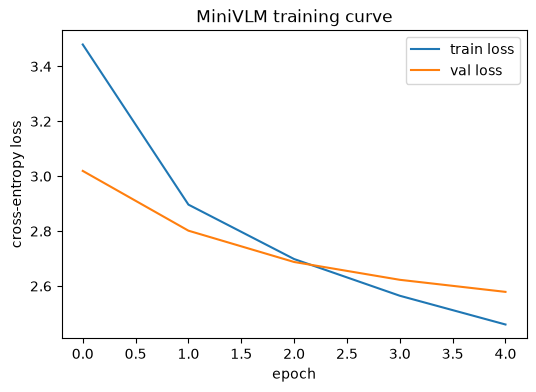

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train loss")
plt.plot(history["val_loss"], label="val loss")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("MiniVLM training curve")
plt.legend()
plt.show()


## 11. Inference: generate a caption for a sample image

Greedy decoding (always pick the highest-probability next token) for simplicity. This is the "does it actually work" moment -- expect rough, sometimes repetitive captions at this scale/data size, but they should be recognizably related to the image content once training has converged even partially.

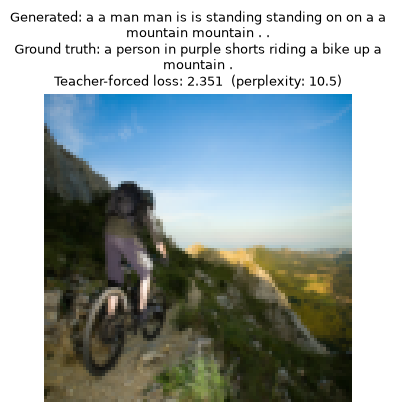

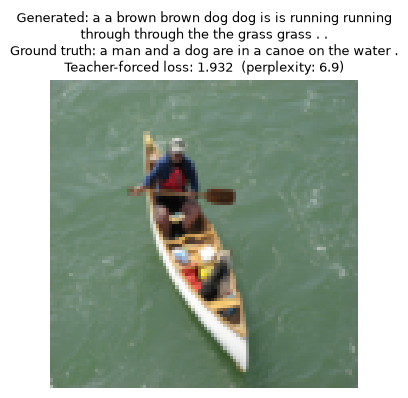

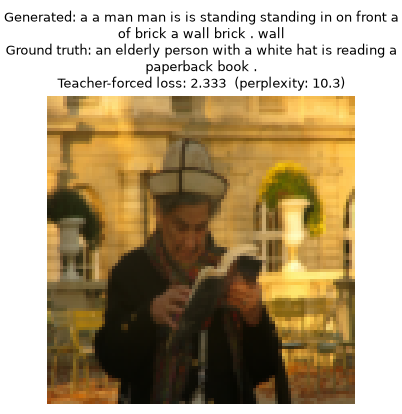

In [11]:
@torch.no_grad()
def caption_loss(image_tensor, gt_token_ids):
    """Teacher-forced cross-entropy loss for one (image, ground-truth caption) pair --
    the same objective run_epoch() averages over a whole loader, computed here for a
    single example so it can sit next to the qualitative generated caption below."""
    model.eval()
    images = image_tensor.unsqueeze(0).to(device)
    token_ids = gt_token_ids.unsqueeze(0).to(device)
    logits = model(images, token_ids)
    loss = loss_fn(logits.reshape(-1, vocab_size), token_ids.reshape(-1))
    return loss.item()


def show_prediction(dataset_obj, idx):
    image_tensor, gt_token_ids = dataset_obj[idx]
    generated_ids = model.generate(
        image_tensor.to(device), bos_id=tokenizer.bos_id, eos_id=tokenizer.eos_id, max_new_tokens=MAX_TEXT_LEN
    )
    caption = tokenizer.decode(generated_ids.tolist())
    ground_truth = tokenizer.decode(gt_token_ids.tolist())
    loss = caption_loss(image_tensor, gt_token_ids)
    perplexity = math.exp(loss)

    # Unnormalize for display
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img_display = (image_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

    plt.figure(figsize=(4, 4))
    plt.imshow(img_display)
    plt.axis("off")
    plt.title(
        f"Generated: {caption}\nGround truth: {ground_truth}\n"
        f"Teacher-forced loss: {loss:.3f}  (perplexity: {perplexity:.1f})",
        fontsize=9, wrap=True,
    )
    plt.show()


# Try a few random validation examples
for i in random.sample(range(len(val_set)), min(3, len(val_set))):
    show_prediction(val_set.dataset, val_set.indices[i])


## 12. Quantitative comparison: fixed-set BLEU-4 (via `eval_utils.py`)

The teacher-forced loss/perplexity above is scored against this notebook's own ~5,240-word vocabulary, which makes it meaningless to compare directly against the LLaVA-style notebooks' numbers (scored against SmolLM2's ~49K-token vocabulary instead) -- see `eval_utils.py`'s module docstring for the full argument.

`evaluate_fixed_set` sidesteps that by running *free generation* (not teacher-forced) on the same fixed set of 10 validation images every notebook uses, and scoring the results with corpus BLEU-4 against Flickr8k's real reference captions. BLEU-4 doesn't care about a model's internal vocabulary size, so it's the number that's actually fair to put side by side with `minimal_vlm_llava_style.ipynb` and `minimal_vlm_llava_stage2_lora.ipynb`.

In [13]:
import sys
sys.path.insert(0, ".")  # adjust if eval_utils.py lives elsewhere

# Reload in case this kernel already imported an older eval_utils.py earlier in
# this session -- Python caches modules, so editing the file on disk alone
# wouldn't be picked up by an already-running kernel without this.
import importlib
import eval_utils
importlib.reload(eval_utils)
from eval_utils import evaluate_fixed_set, build_reference_lookup, save_result

reference_lookup = build_reference_lookup(CAPTIONS_FILE)

def generate_and_decode(val_set, idx):
    image_tensor, _gt_token_ids = val_set.dataset[val_set.indices[idx]]
    generated_ids = model.generate(
        image_tensor.to(device), bos_id=tokenizer.bos_id, eos_id=tokenizer.eos_id,
        max_new_tokens=MAX_TEXT_LEN,
    )
    return tokenizer.decode(generated_ids.tolist())

from_scratch_results = evaluate_fixed_set(val_set, generate_and_decode, reference_lookup)
print(f"\nFrom-scratch corpus BLEU-4 on fixed set: {from_scratch_results['bleu4']:.4f}")

# Persist to the shared comparison file (see "Where can I see the comparison?" --
# each notebook runs in its own kernel, so this file is what ties all three together).
save_result("From-scratch", from_scratch_results)


Corpus BLEU-4 over 10 fixed images: 0.0098

  [1459032057_97e73ed6ab.jpg]
    generated: a a man man and and a a woman woman are are sitting sitting on on a a bench bench . .
    reference: A girl in a striped shirt holds a bun to her mouth .
  [1178705300_c224d9a4f1.jpg]
    generated: a a boy boy is is jumping jumping into into a a pool pool . .
    reference: a brown dog jumping into a pool after a bloe ball .
  [2206594874_5e0087c6b7.jpg]
    generated: a a man man and and a a woman woman are are sitting sitting on on a a bench bench . .
    reference: A couple sits at a cramped table in a busy restaurant .
  [3376809186_4e26d880b7.jpg]
    generated: a a man man is is doing doing a a trick trick on on a a skateboard skateboard . .
    reference: A group of people are in the water .
  [783994497_4f6885454d.jpg]
    generated: a a man man and and a a woman woman are are sitting sitting on on a a bench bench . .
    reference: A group of people are getting fountain drinks at a conven

## 13. Notes for the reading log / report

A few things worth capturing when you write this up alongside the paper summaries:

- **What this is a small version of:** vision encoder (ViT, like CLIP's) → projector (linear layer, like LLaVA's) → text decoder (stands in for a pretrained LLM). The *shape* of the pipeline is the same as every paper reviewed in Week 1; the scale and the fact that nothing is pretrained are the differences.
- **What's simplified vs. production VLMs:**
  - No pretrained vision encoder (CLIP-style contrastive pretraining) — this ViT starts from random weights and learns visual features purely from the captioning objective, which is much weaker supervision than CLIP's 400M-pair contrastive pretraining.
  - No pretrained LLM — production VLMs (LLaVA, Qwen2.5-VL, etc.) bolt their connector onto an already-fluent language model. Here the "LLM" is trained from scratch alongside everything else, on a tiny dataset, so its language fluency will be noticeably weaker.
  - Word-level tokenizer instead of subword/BPE — fine at this scale, would not scale to a larger vocabulary or multiple languages.
- **What would change if scaling this up:** swap in a pretrained ViT (e.g. initialize `ViTEncoder`'s weights from a small pretrained model) and/or a small pretrained LLM, freeze one or both, and only train the projector first (mirroring LLaVA's stage-1 feature-alignment training) before unfreezing more of the stack.
- **Suggested figure for the report:** the training curve from Section 10, plus 2-3 generated-vs-ground-truth caption examples from Section 11, as a concrete "it works, here's the evidence" artifact, plus the fixed-set BLEU-4 from Section 12 as the quantitative headline number that's actually comparable against the LLaVA-style notebooks.
